# Average 24-Hour Electricity Consumption Profile

This notebook calculates the average energy consumption at each **UTC hour of the day** for a single development household over the **January–August 2013 training period**.

**Outputs:** `figures/daily_profile.png` and `figures/daily_profile_notes.md`.

Run the cells in order. Paths assume the notebook is located **two directory levels beneath the project root**, matching the original code.

## 1. Import libraries and configure paths

Prepare the data-processing libraries, input paths and chart output directory.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# This notebook is intended to run from notebooks/<subfolder>/, as in the original scripts.
PROJECT_ROOT = Path("../..").resolve()
HOURLY_PATH = PROJECT_ROOT / "data/processed/hourly_readings.csv"
SPLIT_PATH = PROJECT_ROOT / "data/household_split.csv"
OUT_DIR = PROJECT_ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the data and identify development households

Convert hourly timestamps to UTC and energy readings to numeric values. Select household IDs assigned to the `DEVELOPMENT` split.

In [3]:
hourly = pd.read_csv(HOURLY_PATH)
hourly["hour_start"] = pd.to_datetime(hourly["hour_start"], utc=True)
hourly["kWh"] = pd.to_numeric(hourly["kWh"], errors="coerce")

splits = pd.read_csv(SPLIT_PATH)
dev_homes = splits.loc[
    splits["Cohort"].str.upper() == "DEVELOPMENT", "LCLid"
].tolist()

if not dev_homes:
    raise ValueError("No DEVELOPMENT households were found in household_split.csv")

print(f"Loaded {len(hourly):,} hourly rows and {len(dev_homes):,} development households.")

Loaded 2,628,000 hourly rows and 240 development households.


## 3. Filter one household to the training period

Choose the **first development household**, matching the time-curve notebook. Include **January 1–August 31, 2013**, using a September 1 exclusive cutoff.

In [4]:
sample_home = dev_homes[0]
train_start = pd.Timestamp("2013-01-01", tz="UTC")
train_end = pd.Timestamp("2013-09-01", tz="UTC")

home_train = hourly.loc[
    (hourly["LCLid"] == sample_home)
    & (hourly["hour_start"] >= train_start)
    & (hourly["hour_start"] < train_end)
].copy()

print(f"Household: {sample_home} | Training rows: {len(home_train):,}")

Household: MAC000038 | Training rows: 5,832


## 4. Calculate the 24-hour average profile

Group the household's readings by hour (`0`–`23`, UTC). For each hour, calculate the **mean of valid kWh values** and the **number of non-missing observations**. Reindexing ensures all 24 hours appear even when there are no valid readings for some hours.

In [5]:
home_train["hour_of_day"] = home_train["hour_start"].dt.hour

profile = (
    home_train.groupby("hour_of_day")["kWh"]
    .agg(mean_hourly_kwh="mean", available_observations="count")
    .reindex(range(24))
    .reset_index()
)
profile.insert(0, "LCLid", sample_home)

min_obs = int(profile["available_observations"].min())
max_obs = int(profile["available_observations"].max())
profile

,LCLid,hour_of_day,mean_hourly_kwh,available_observations
0,MAC000038,0,0.179785,242
1,MAC000038,1,0.150317,243
2,MAC000038,2,0.149914,243
3,MAC000038,3,0.208436,243
4,MAC000038,4,0.271091,243
5,MAC000038,5,0.320477,243
6,MAC000038,6,0.413226,243
7,MAC000038,7,0.459132,243
8,MAC000038,8,0.441461,243
9,MAC000038,9,0.447642,243


## 5. Visualize the daily consumption pattern

The x-axis represents the **hour of the day in UTC**, not the sequence of days. Each point summarizes all valid readings observed at that hour during the training period. The coverage note describes the range of valid observation counts across the 24 hours.

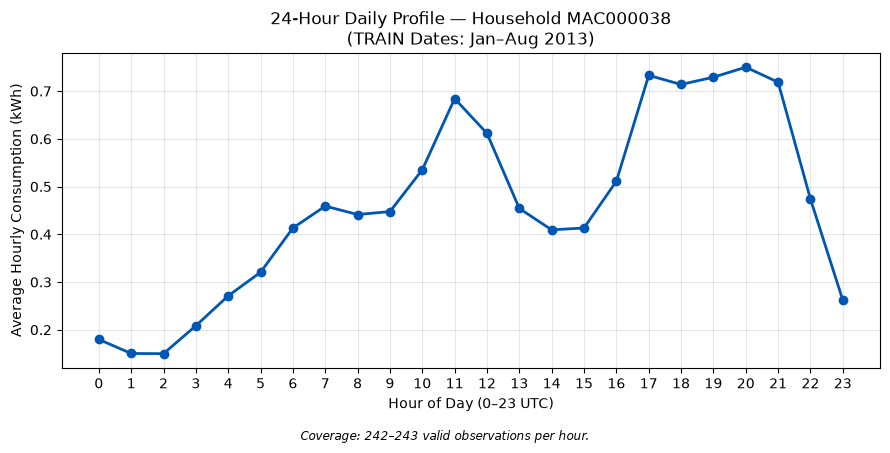

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(profile["hour_of_day"], profile["mean_hourly_kwh"],
        marker="o", linewidth=2, color="#0056b3")
ax.set_title(
    f"24-Hour Daily Profile — Household {sample_home}\n"
    "(TRAIN Dates: Jan–Aug 2013)"
)
ax.set_xlabel("Hour of Day (0–23 UTC)")
ax.set_ylabel("Average Hourly Consumption (kWh)")
ax.set_xticks(range(24))
ax.grid(True, alpha=0.3)
fig.text(0.5, 0.01,
         f"Coverage: {min_obs}–{max_obs} valid observations per hour.",
         ha="center", fontsize=8.5, style="italic")
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(OUT_DIR / "daily_profile.png", dpi=150)
plt.show()

## 6. Export the profile notes

Save a short report-ready Markdown caption with the selected household and observation coverage.

In [7]:
profile_caption = (
    "# M5 Week 2 Daily Profile\n"
    f"Household {sample_home}, TRAIN period (Jan–Aug 2013). "
    "Shows average kWh for each hour (0–23 UTC). "
    f"Valid observations per hour range from {min_obs} to {max_obs}. "
    "Missing readings are excluded from the mean calculation."
)
notes_path = OUT_DIR / "daily_profile_notes.md"
notes_path.write_text(profile_caption, encoding="utf-8")
print(f"Saved chart and notes to: {OUT_DIR}")

Saved chart and notes to: C:\Projects\Data mining project\household-energy-prediction\figures
